# Regression Comparison California Housing Data
A review of several regression algorithms on the California Housing Data Set

## Imports and Setup

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


### Helper Functions

In [4]:
# function to plot a boxplot and a histogram along the same scale for all numeric features
def histogram_boxplot(data, feature, figsize=(12, 7), kde=True, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to the show density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a star will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, color="seagreen"
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

In [5]:
base_df = pd.read_csv('ca_housing.csv')
base_df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


### Data Dictionary
+ **longitude:** A measure of how far west a house is; a higher value is farther west
+ **latitude:** A measure of how far north a house is; a higher value is farther north
+ **housingMedianAge:** Median age of a house within a block; a lower number is a newer building
+ **totalRooms:** Total number of rooms within a block
+ **totalBedrooms:** Total number of bedrooms within a block
+ **population:** Total number of people residing within a block
+ **households:** Total number of households, a group of people residing within a home unit, for a block
+ **medianIncome:** Median income for households within a block of houses (measured in tens of thousands of US Dollars)
+ **medianHouseValue:** Median house value for households within a block (measured in US Dollars)
+ **oceanProximity:** Location of the house w.r.t ocean/sea

## EDA and Data Prep
### Data Summary

In [6]:
base_df.shape

(20640, 10)

The shape of the dataset indicates that there are 12 columns (features) and 20,640 rows (observations).

In [7]:
base_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB


All of the features, except 1, are float. The remaining feature is a string and will need to be encoded. 

Only one feature has missing values that will need to be addressed. 

In [8]:
base_df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


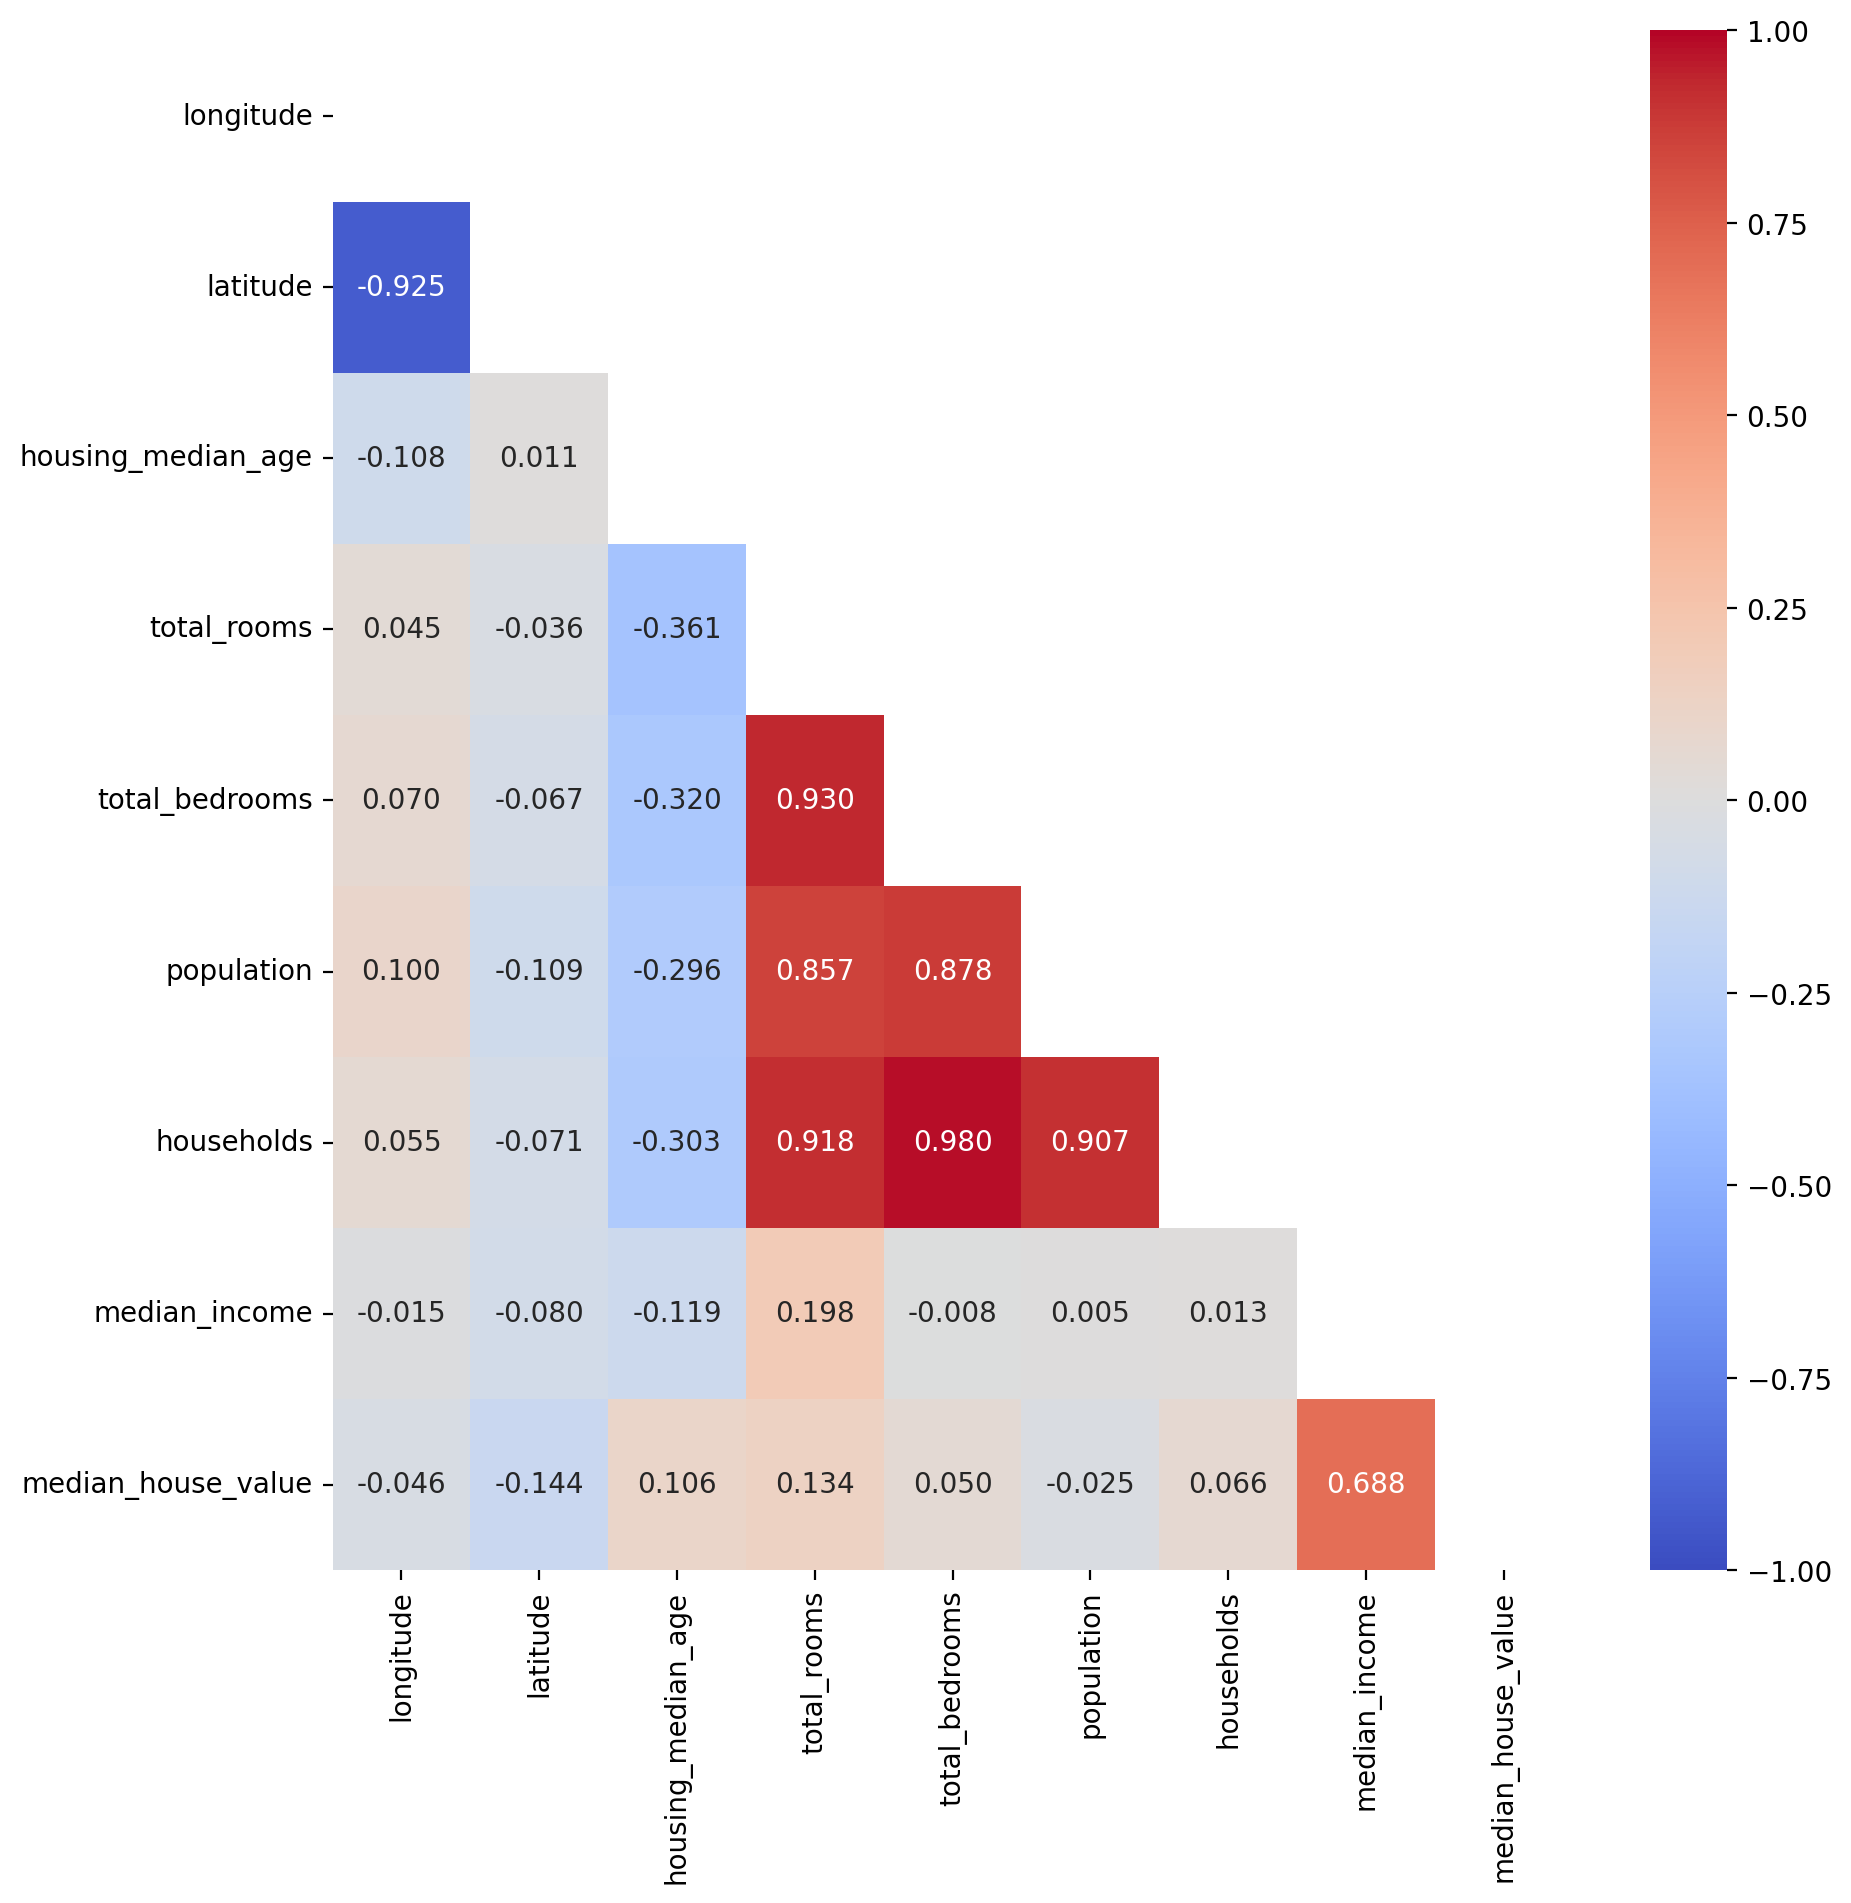

In [9]:
corr = base_df.select_dtypes(include="number").corr()
plt.figure(figsize=(10,10), dpi=200)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(data=corr, vmin=-1, vmax=1, annot=True, cmap="coolwarm",fmt=".3f", mask=mask);

In [10]:
analysis_df = base_df.drop(columns=['longitude', 'latitude'])

The correlation coeffiecients on the initial heatmap indicate that certain feature have a very high correlation. Will need to review the distribution of the features.

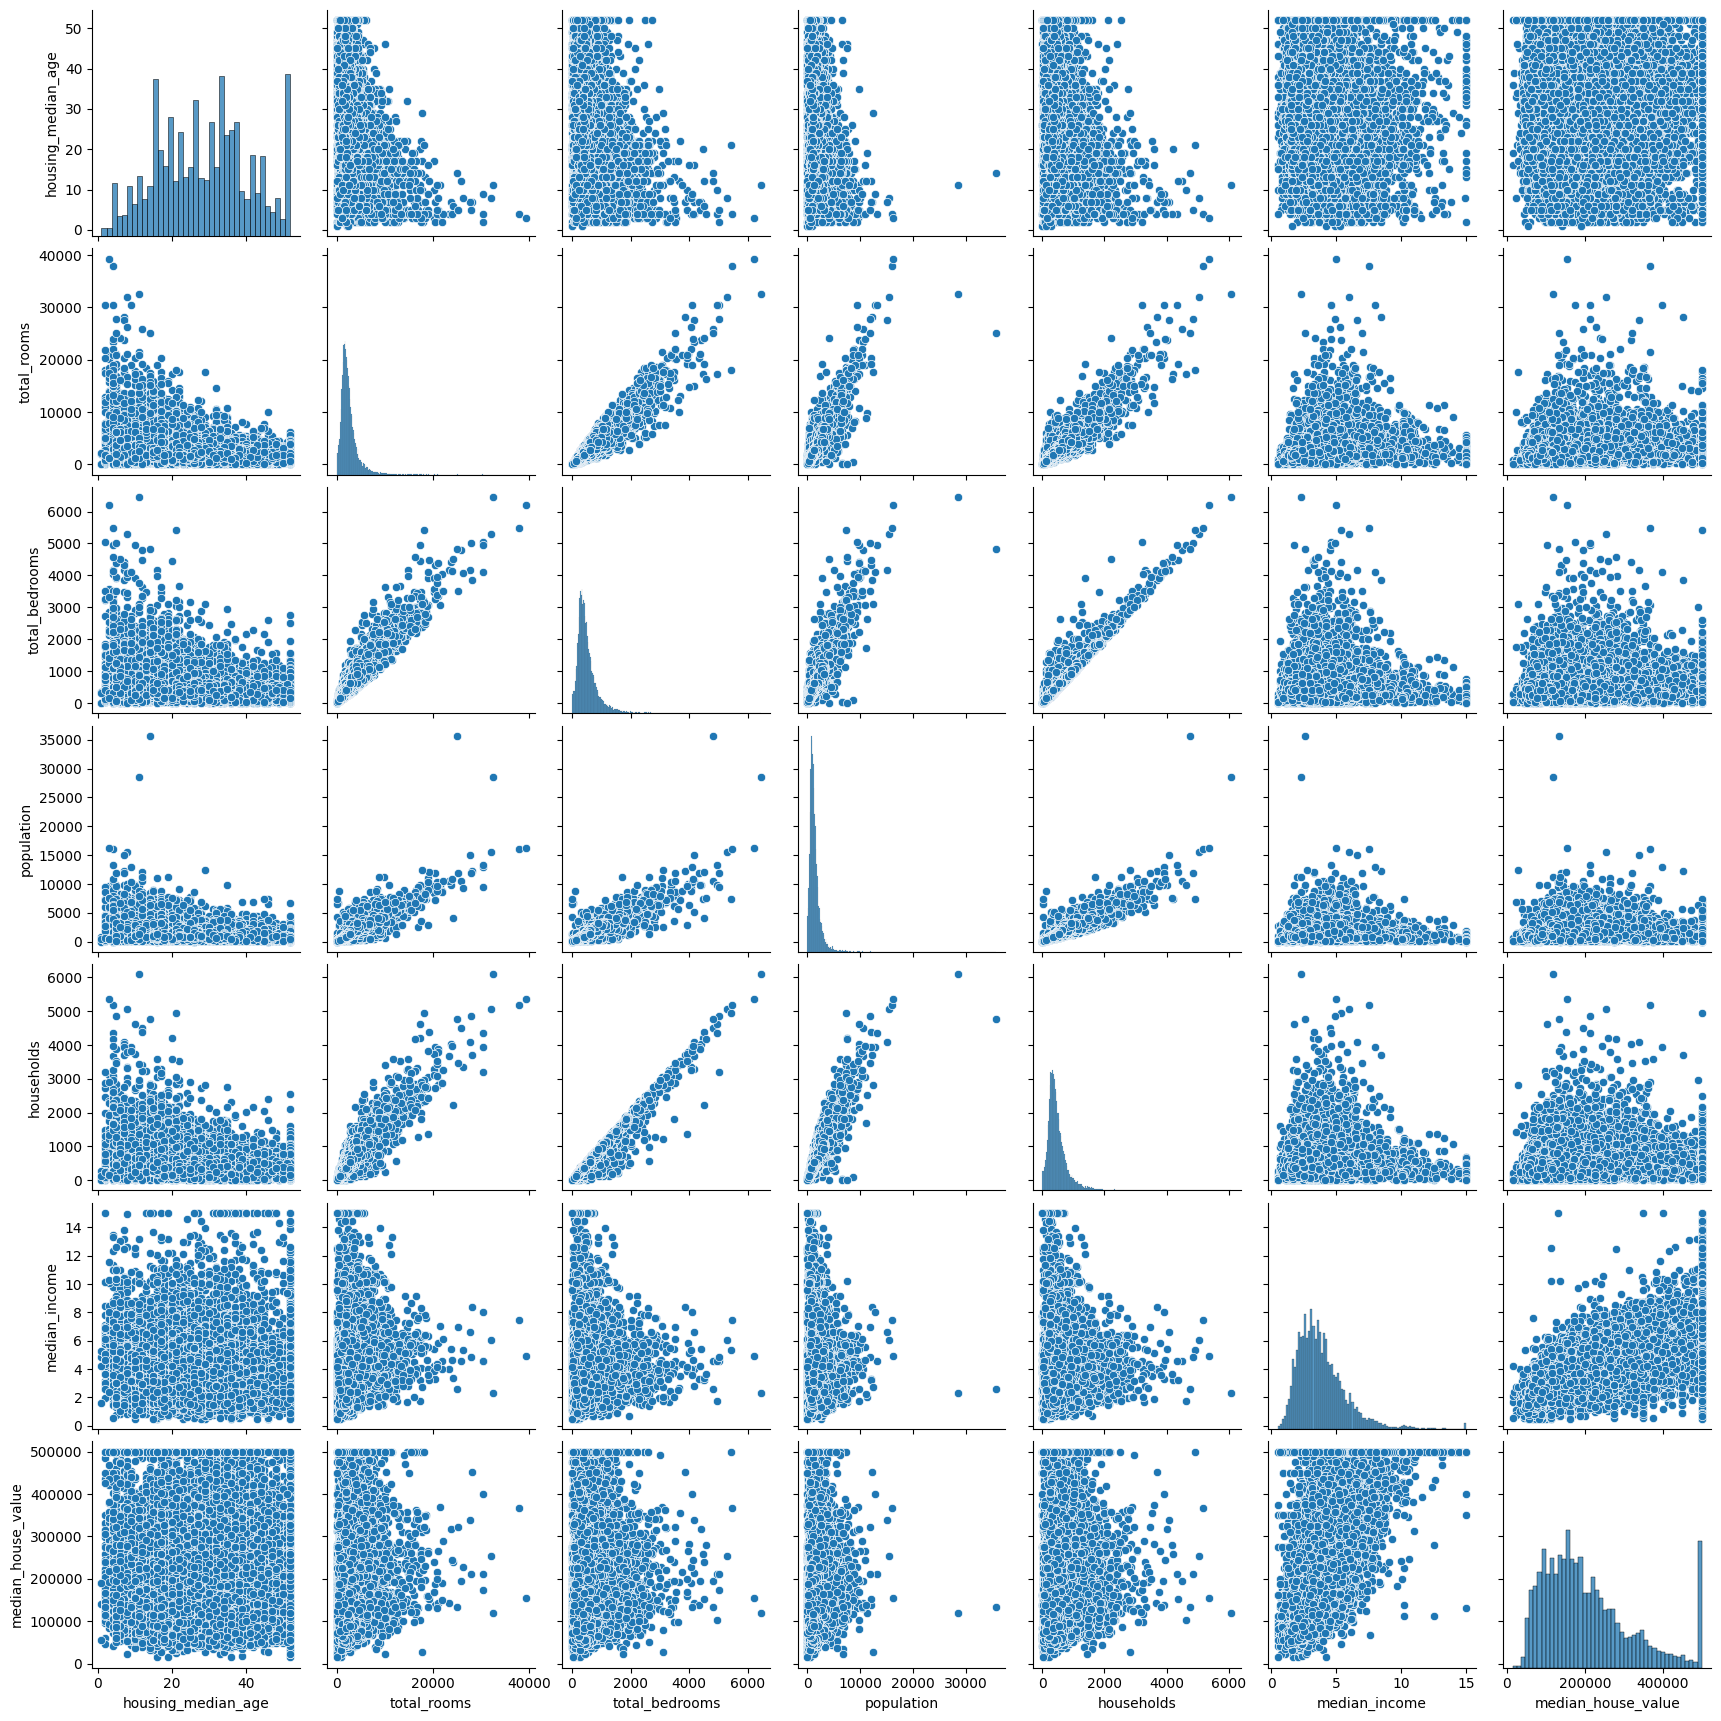

In [11]:
sns.pairplot(data=analysis_df);

### Numeric feature review

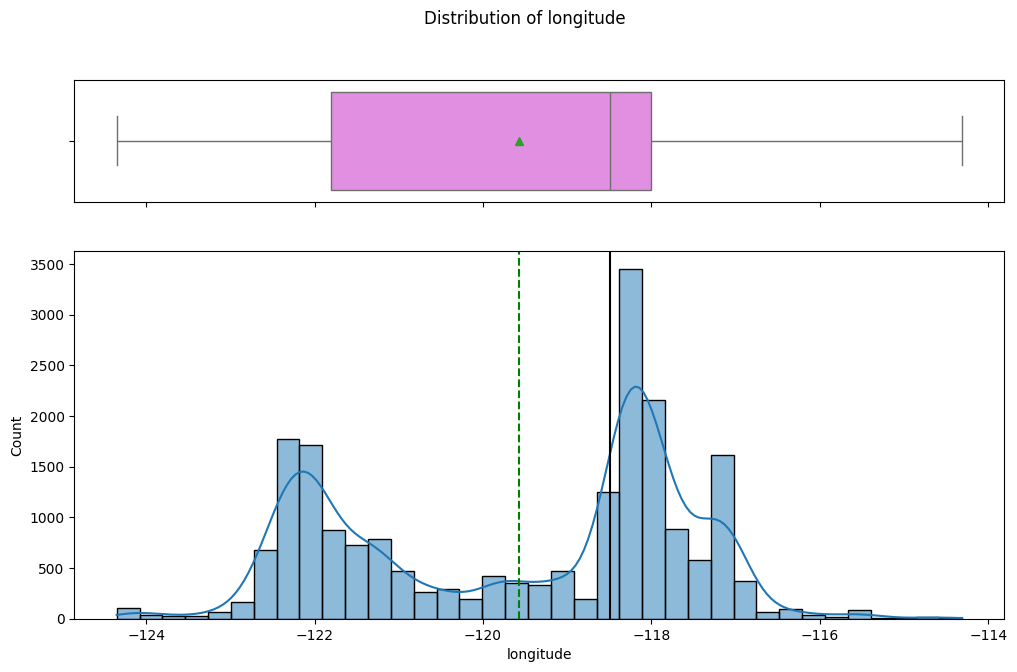

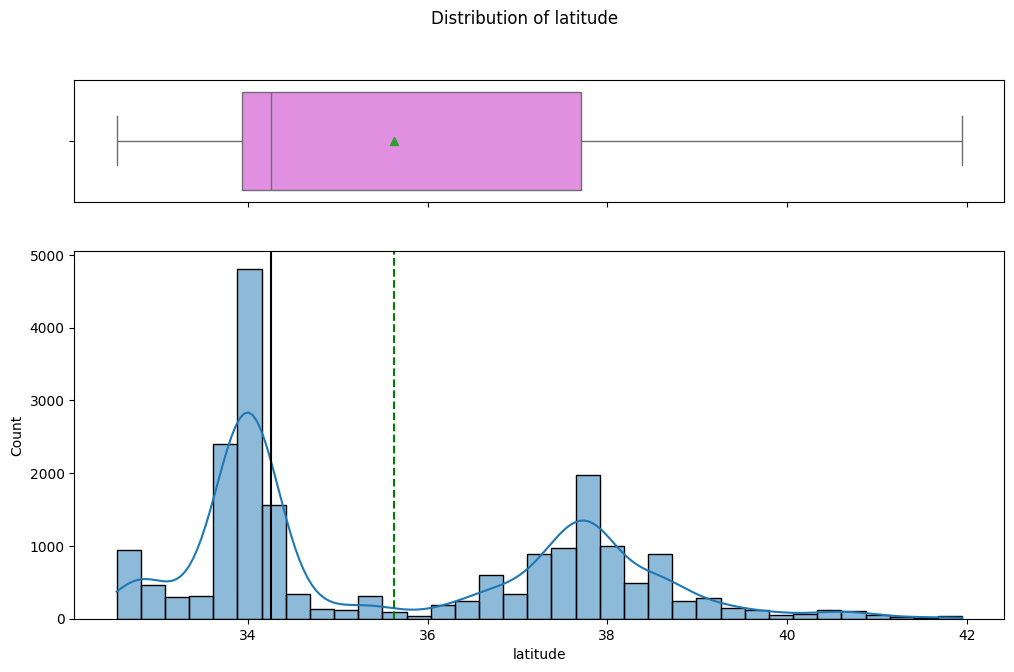

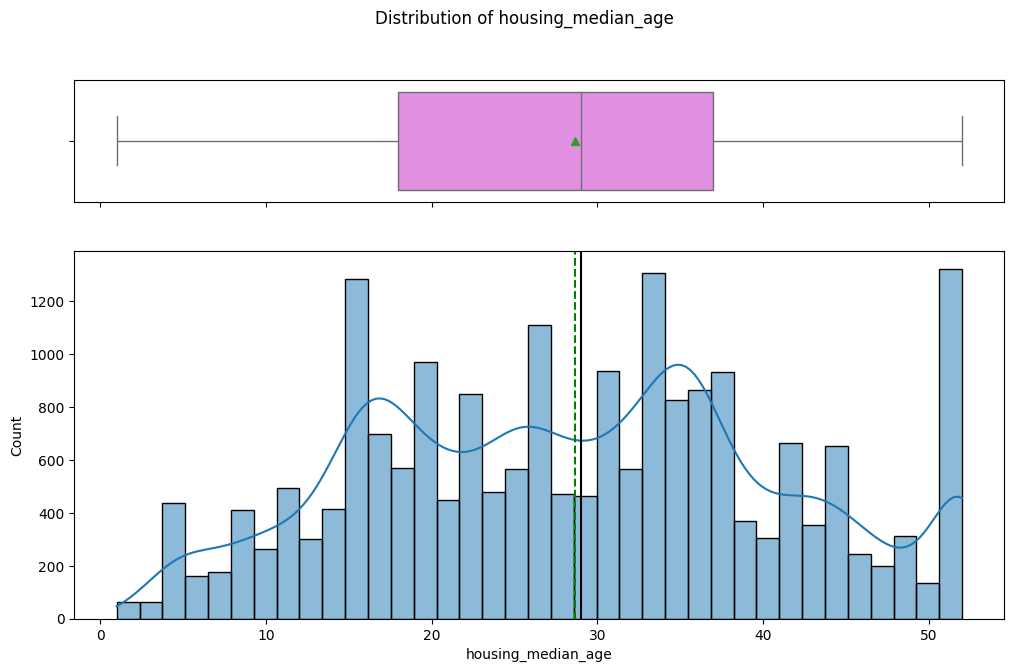

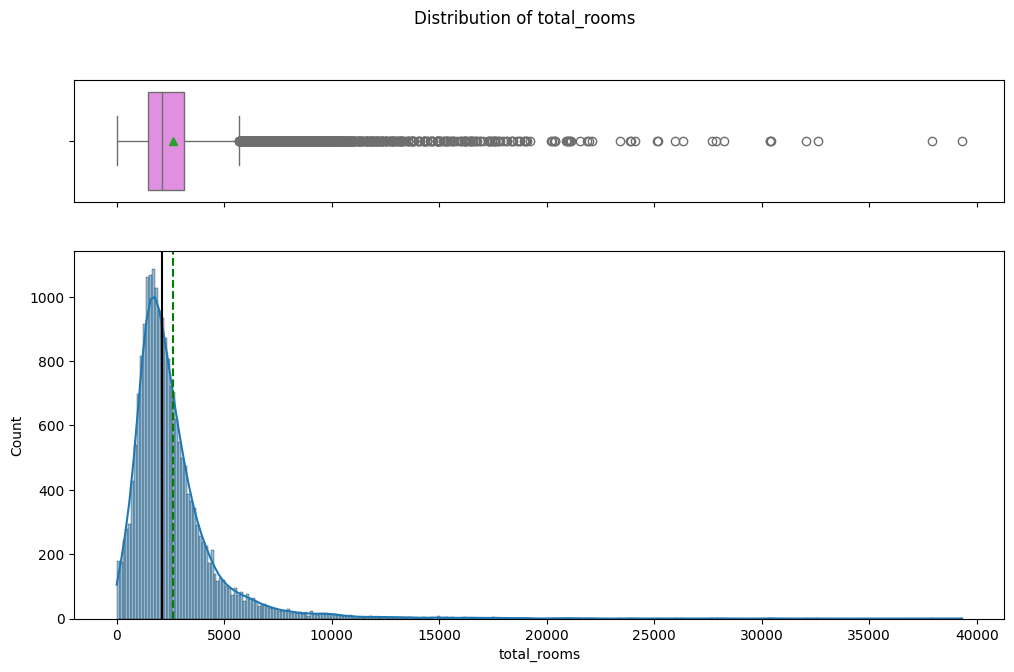

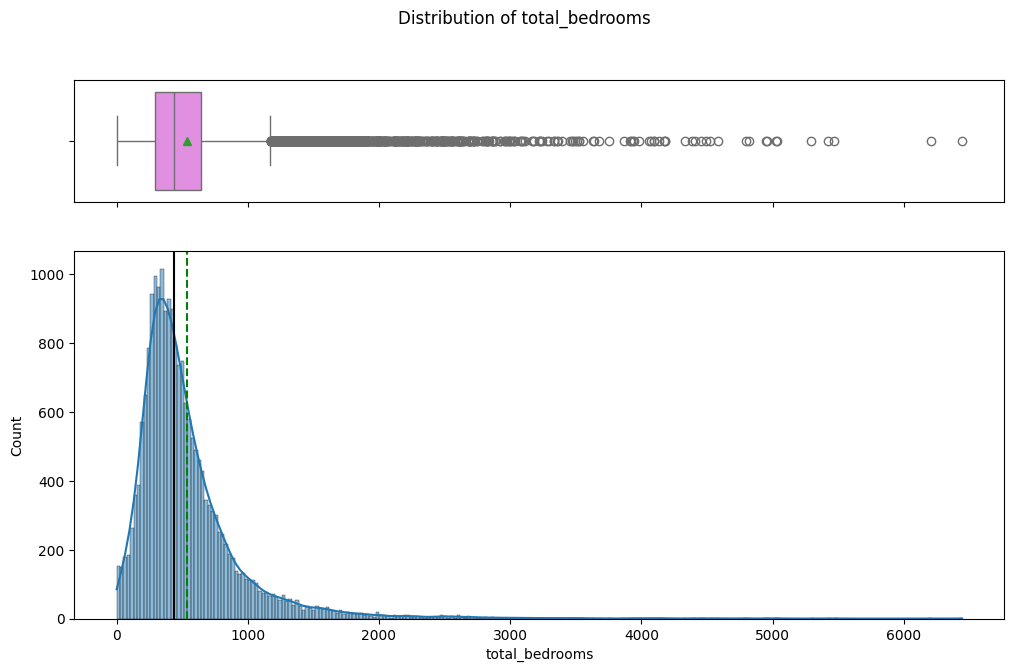

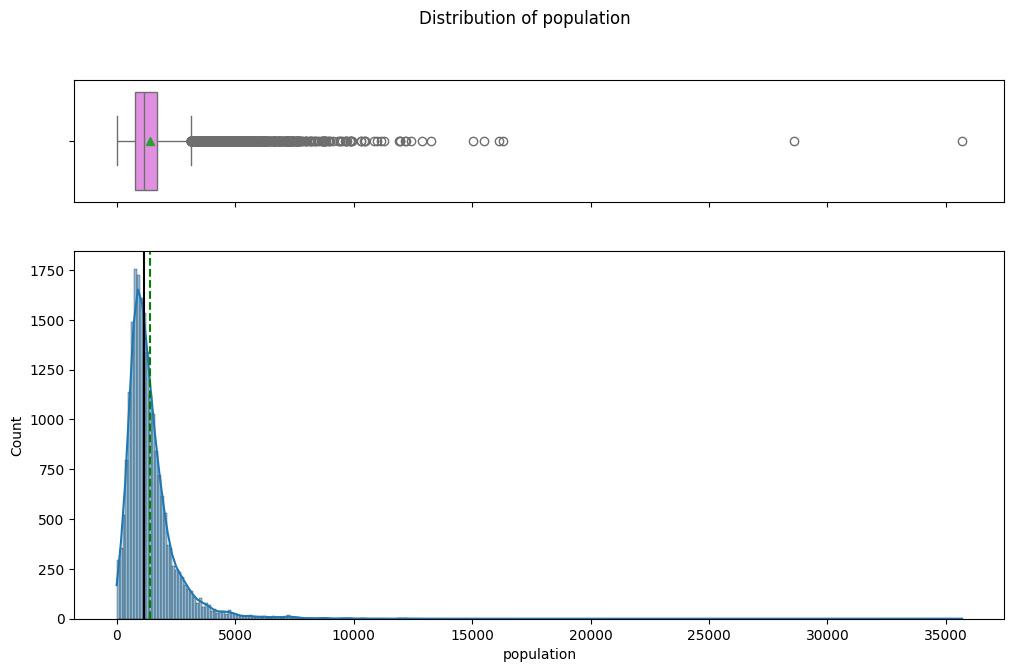

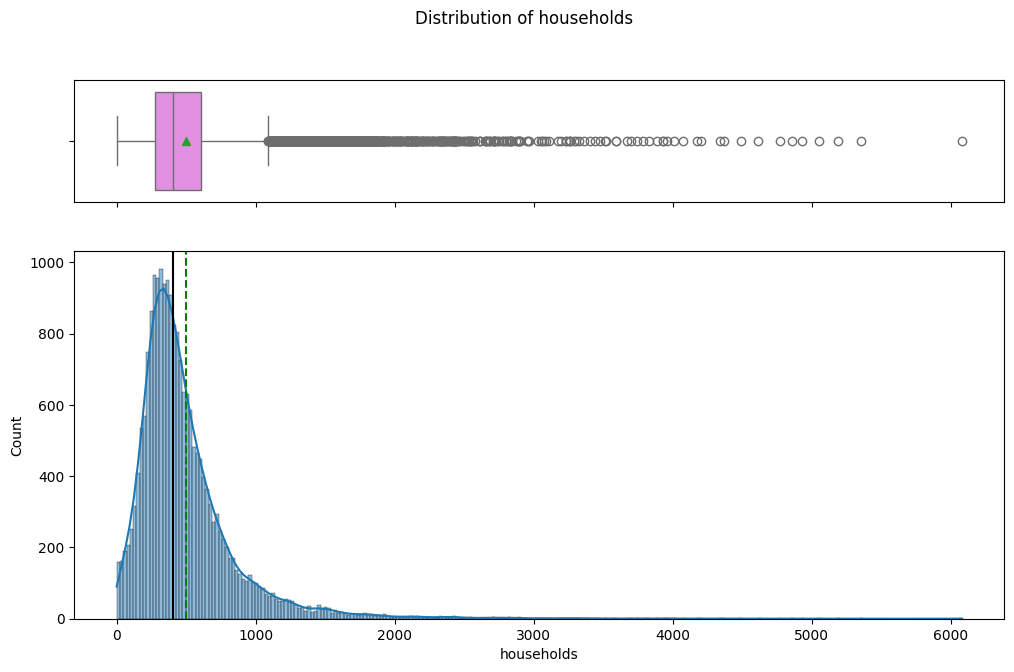

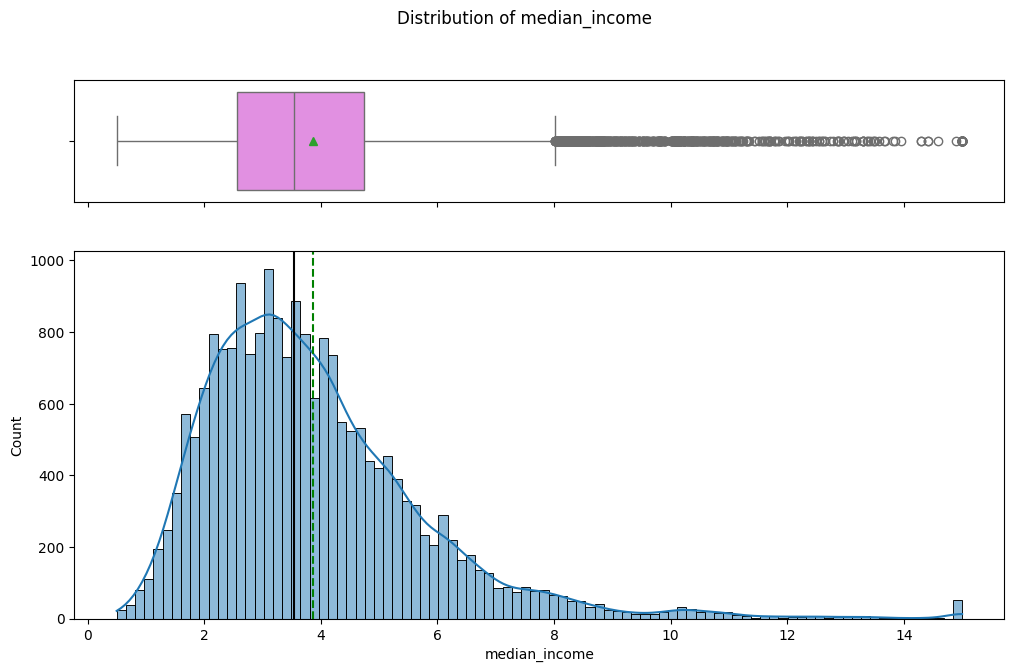

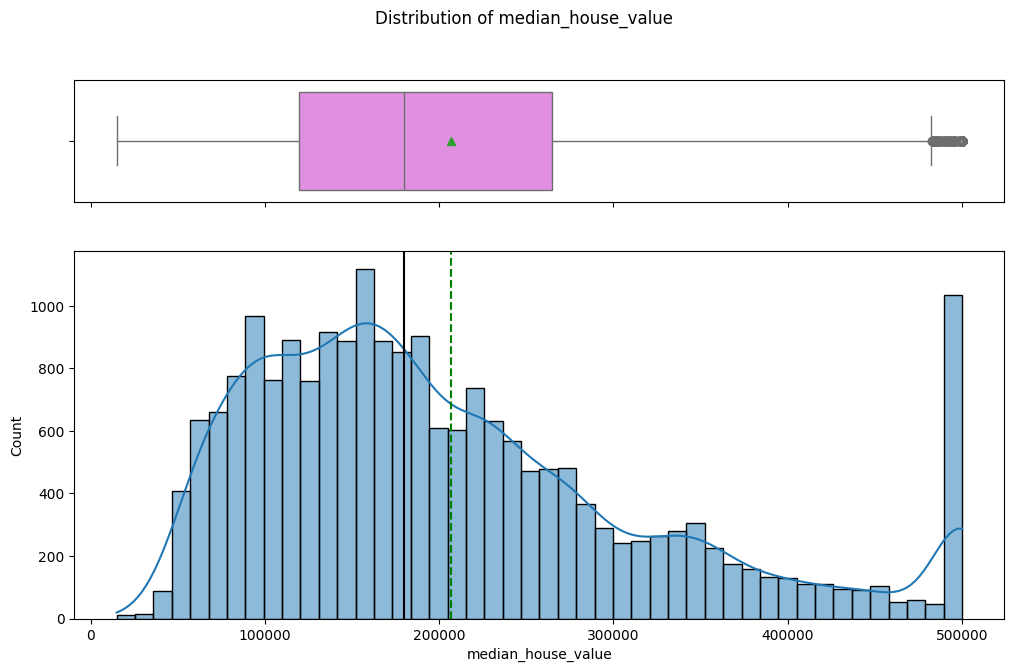

In [13]:
# Select only the numerical columns
num_cols = base_df.select_dtypes(include=np.number).columns.tolist()

for col in num_cols:
    histogram_boxplot(base_df, col)
    plt.suptitle(f"Distribution of {col}")
    plt.show()